# Tugas — Studi Ablasi RNN, LSTM, GRU vs ANN

**Workshop Deep Learning · Teknik Telekomunikasi ITERA · Tenggat: Rabu, 28 Oktober 2026, 23.59 WIB**

Di Sesi 2 kita membandingkan ANN, RNN, LSTM, dan GRU dengan **satu** konfigurasi. Pertanyaan tugas ini: **seberapa besar hasil itu bergantung pada pilihan hyperparameter?** Kalian akan mengubah **satu faktor dalam satu waktu** dari konfigurasi acuan (*studi ablasi*), mencari konfigurasi terbaik memakai data **validasi**, lalu menguji apakah konfigurasi itu juga bagus di lokasi lain di Milan.

| Bagian | Isi | Status |
|---|---|---|
| 0 | Konfigurasi acuan & baseline naif | wajib |
| A | Ablasi 5 faktor: jendela W, ukuran hidden, jumlah lapisan, *learning rate*, kelompok fitur | wajib |
| B | Ablasi **minimal 2** faktor tambahan pilihan kelompok | wajib (pilih) |
| C | Konfigurasi terbaik per model (dipilih dengan **val MAE**) → uji di minggu test & Natal | wajib |
| D | Uji generalisasi di **lokasi kelompok** | wajib |

**Aturan main**

1. Jalankan sel dari atas ke bawah. Fungsi inti (data, model, training) **jangan diubah**, kecuali untuk faktor Bagian B yang memang membutuhkannya. Bila mengubah, jelaskan di laporan.
2. Semua run otomatis dicatat ke `hasil/ablasi.csv`. Run yang sudah ada **dilewati**, jadi notebook aman dijalankan ulang bila terputus (misalnya di Colab).
3. Setiap konfigurasi dilatih dengan **3 seed**. Laporkan **rata-rata ± simpangan baku**, bukan hasil satu run.
4. Pilih konfigurasi terbaik dengan **val MAE**. Minggu test & Natal hanya untuk pelaporan akhir. Memilih berdasarkan test = mengintip kunci jawaban.
5. Commit notebook **beserta output-nya** dan seluruh isi folder `hasil/` ke repo kelompok.

In [1]:
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# ---- ISI DULU ----
LOKASI_KELOMPOK = 6    # kode 0–9 = digit terakhir NIM terkecil di kelompok, contoh: 7

# ---- Pengaturan umum ----
CEPAT = False             # True = 1 seed & 20 epoch, HANYA untuk mencoba kode. Hasil akhir wajib CEPAT = False.
SEEDS = [0] if CEPAT else [0, 1, 2]
MODELS = ["ANN", "RNN", "LSTM", "GRU"]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
HASIL_DIR = Path("hasil")
HASIL_DIR.mkdir(exist_ok=True)
CSV_HASIL = HASIL_DIR / ("ablasi_cepat.csv" if CEPAT else "ablasi.csv")

NAVY, GOLD, RED, TEAL, GRAY = "#0B1F3A", "#D4A017", "#C8102E", "#1E8C8C", "#5A5A5A"
WARNA_MODEL = {"ANN": GOLD, "RNN": RED, "LSTM": NAVY, "GRU": TEAL}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

assert LOKASI_KELOMPOK in range(10), "Isi LOKASI_KELOMPOK dengan kode lokasi kelompok (0-9)"
print("PyTorch", torch.__version__, "| device:", DEVICE, "| hasil ->", CSV_HASIL)

PyTorch 2.15.0+cpu | device: cpu | hasil -> hasil\ablasi.csv


---
## 1. Data

- `data/milano_duomo_5060.csv`: kotak Duomo, sama dengan Sesi 2 (dipakai di Bagian 0–C).
- `data/milano_tugas_10_lokasi.csv`: 10 lokasi lain (kolom `kode` 0–9), dipakai di Bagian D.

Pembagian waktu sama dengan Sesi 2: train 11 Nov – 8 Des, val 9 – 15 Des, test 16 – 22 Des, Natal 23 – 29 Des. Minggu pertama (4 – 10 Nov) hanya menjadi konteks jendela.

Kelompok fitur yang bisa dipilih (faktor A5):

| Nama | Fitur |
|---|---|
| `net` | net |
| `net+call+sms` | net, call, sms |
| `net+waktu` | net, jam (sin, cos), hari (sin, cos) |
| `semua` | net, call, sms, jam (sin, cos), hari (sin, cos) — **acuan** |

In [2]:
LOKASI = pd.read_csv("data/milano_tugas_10_lokasi.csv", usecols=["kode", "lokasi", "kotak"]).drop_duplicates().set_index("kode")
WAKTU = ["jam_sin", "jam_cos", "hari_sin", "hari_cos"]
KELOMPOK_FITUR = {
    "net": ["net"],
    "net+call+sms": ["net", "call", "sms"],
    "net+waktu": ["net"] + WAKTU,
    "semua": ["net", "call", "sms"] + WAKTU,
}
TARGET = "net"

def muat_data(lokasi):
    """lokasi = "duomo" atau kode 0–9. Mengembalikan DataFrame per jam dengan 7 kolom fitur."""
    if lokasi == "duomo":
        df = pd.read_csv("data/milano_duomo_5060.csv", parse_dates=["waktu"])
    else:
        df = pd.read_csv("data/milano_tugas_10_lokasi.csv", parse_dates=["waktu"])
        df = df[df.kode == lokasi].drop(columns=["kode", "lokasi", "kotak"])
    df = df.set_index("waktu")
    jam, hari = df.index.hour.values, df.index.day_of_week.values
    df["jam_sin"], df["jam_cos"] = np.sin(2 * np.pi * jam / 24), np.cos(2 * np.pi * jam / 24)
    df["hari_sin"], df["hari_cos"] = np.sin(2 * np.pi * hari / 7), np.cos(2 * np.pi * hari / 7)
    return df

def nama_lokasi(lokasi):
    return "Duomo" if lokasi == "duomo" else LOKASI.loc[lokasi, "lokasi"]

LOKASI.assign(kelompok_kalian=lambda d: np.where(d.index == LOKASI_KELOMPOK, "<--", ""))

,lokasi,kotak,kelompok_kalian
kode,,,
0,Stazione Centrale,6165,
1,Navigli (Darsena),4555,
2,Universita Bocconi,4460,
3,Stadio San Siro,5738,
4,Politecnico di Milano,5772,
5,Bandara Linate,4489,
6,Parco Sempione,5455,<--
7,Universita Bicocca,7467,
8,CityLife,5749,


In [3]:
_CACHE = {}

def siapkan(lokasi, fitur):
    """Standarisasi dengan statistik sebelum minggu validasi (tidak mengintip masa depan)."""
    kunci = (lokasi, fitur)
    if kunci not in _CACHE:
        df = muat_data(lokasi)
        kolom = KELOMPOK_FITUR[fitur]
        t = df.index
        split = {
            "train": (t >= "2013-11-11") & (t < "2013-12-09"),
            "val":   (t >= "2013-12-09") & (t < "2013-12-16"),
            "test":  (t >= "2013-12-16") & (t < "2013-12-23"),
            "natal": (t >= "2013-12-23"),
        }
        sebelum_val = t < "2013-12-09"
        mean, std = df.loc[sebelum_val, kolom].mean(), df.loc[sebelum_val, kolom].std()
        Z = ((df[kolom] - mean) / std).values.astype(np.float32)
        _CACHE[kunci] = dict(Z=Z, net=df[TARGET].values, split=split, mean=mean[TARGET], std=std[TARGET],
                             i_target=kolom.index(TARGET), waktu=t)
    return _CACHE[kunci]


def buat_jendela(d, W, nama_split, H):
    """Titik awal i: X = Z[i-W:i], y = net terstandarisasi jam i … i+H-1.
    Sampel masuk split bila jam target terakhirnya (i+H-1) ada di split tersebut."""
    awal = np.arange(W, len(d["Z"]) - H + 1)
    awal = awal[d["split"][nama_split][awal + H - 1]]
    X = np.stack([d["Z"][i - W:i] for i in awal])
    y = np.stack([d["Z"][i:i + H, d["i_target"]] for i in awal])
    return torch.tensor(X), torch.tensor(y), awal


def metrik(y_asli, y_pred):
    e = y_pred - y_asli
    return {"MAE": float(np.mean(np.abs(e))), "RMSE": float(np.sqrt(np.mean(e ** 2))),
            "MAPE": float(np.mean(np.abs(e) / y_asli) * 100)}


def baseline_naif(lokasi, H=1):
    """MAE/RMSE/MAPE tiga tebakan tanpa belajar, di split val, test, dan natal."""
    d = siapkan(lokasi, "semua")
    baris = []
    for nama_split in ["val", "test", "natal"]:
        _, _, awal = buat_jendela(d, 168, nama_split, H)
        asli = d["net"][awal[:, None] + np.arange(H)]
        tebakan = {
            "Naif: nilai terakhir": np.repeat(d["net"][awal - 1][:, None], H, axis=1),
            "Naif: kemarin": d["net"][awal[:, None] + np.arange(H) - 24],
            "Naif: minggu lalu": d["net"][awal[:, None] + np.arange(H) - 168],
        }
        for nama, pred in tebakan.items():
            baris.append({"lokasi": nama_lokasi(lokasi), "horizon": H, "model": nama, "split": nama_split, **metrik(asli, pred)})
    return pd.DataFrame(baris)

---
## 2. Model

Sama dengan Sesi 2, ditambah tiga pengaturan: jumlah lapisan (`layers`), ukuran hidden (`hidden`), dan `dropout`.

- **ANN**: jendela `[W, fitur]` diratakan → `layers` lapisan tersembunyi (masing-masing `hidden` neuron, ReLU) → output.
- **RNN / LSTM / GRU**: `layers` lapisan rekuren bertumpuk → *hidden state* jam terakhir → output.
- `dropout` dipasang setelah setiap lapisan tersembunyi ANN, di antara lapisan rekuren, dan sebelum lapisan output.

In [4]:
class ANN(nn.Module):
    def __init__(self, W, n_fitur, n_out, hidden, layers, dropout):
        super().__init__()
        lapis, n_in = [nn.Flatten()], W * n_fitur
        for _ in range(layers):
            lapis += [nn.Linear(n_in, hidden), nn.ReLU(), nn.Dropout(dropout)]
            n_in = hidden
        lapis.append(nn.Linear(n_in, n_out))
        self.net = nn.Sequential(*lapis)
    def forward(self, x):
        return self.net(x)


class Rekuren(nn.Module):
    def __init__(self, jenis, n_fitur, n_out, hidden, layers, dropout):
        super().__init__()
        sel = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[jenis]
        self.rnn = sel(n_fitur, hidden, num_layers=layers, batch_first=True, dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, n_out)
    def forward(self, x):                     # x: [batch, W, fitur]
        out, _ = self.rnn(x)
        return self.head(self.drop(out[:, -1]))


def n_param(model):
    return sum(p.numel() for p in model.parameters())

---
## 3. Konfigurasi Acuan

Semua ablasi berangkat dari konfigurasi ini (= notebook 03 Sesi 2, W = 24). Satu eksperimen hanya mengubah **satu** baris.

| Hyperparameter | Kunci | Acuan | Catatan |
|---|---|---|---|
| Lokasi | `lokasi` | `"duomo"` | Bagian D: kode lokasi kelompok |
| Panjang jendela (jam) | `W` | 24 | |
| Jam yang diramal | `horizon` | 1 | |
| Ukuran hidden | `hidden` | ANN 32, RNN 68, LSTM 33, GRU 38 | acuan dipilih agar parameter rekuren ≈ 5,5 ribu |
| Jumlah lapisan | `layers` | ANN 2, rekuren 1 | |
| Kelompok fitur | `fitur` | `"semua"` | |
| *Learning rate* | `lr` | 0,001 | |
| *Batch size* | `batch` | 64 | |
| Dropout | `dropout` | 0 | |
| Optimizer | `optimizer` | `"adam"` | `"adam"`, `"adamw"` (weight decay 1e-4), `"sgd"` (momentum 0,9) |
| Fungsi loss | `loss` | `"mse"` | `"mse"`, `"mae"`, `"huber"` |
| *Gradient clipping* | `clip` | `None` | contoh: 1.0 |
| *Early stopping patience* | `patience` | 30 | |
| Epoch maksimum | `max_epochs` | 300 | |

In [5]:
ACUAN = dict(lokasi="duomo", W=24, horizon=1, hidden=None, layers=None, fitur="semua", lr=1e-3, batch=64,
             dropout=0.0, optimizer="adam", loss="mse", clip=None, patience=30, max_epochs=300)
HIDDEN_ACUAN = {"ANN": 32, "RNN": 68, "LSTM": 33, "GRU": 38}
LAYERS_ACUAN = {"ANN": 2, "RNN": 1, "LSTM": 1, "GRU": 1}

def lengkapi(cfg, model_nama):
    """hidden/layers = None berarti nilai acuan model tersebut."""
    cfg = {**ACUAN, **cfg}
    if cfg["hidden"] is None:
        cfg["hidden"] = HIDDEN_ACUAN[model_nama]
    if cfg["layers"] is None:
        cfg["layers"] = LAYERS_ACUAN[model_nama]
    if CEPAT:
        cfg["max_epochs"] = min(cfg["max_epochs"], 20)
    return cfg

def buat_model(model_nama, cfg, n_fitur):
    if model_nama == "ANN":
        return ANN(cfg["W"], n_fitur, cfg["horizon"], cfg["hidden"], cfg["layers"], cfg["dropout"])
    return Rekuren(model_nama, n_fitur, cfg["horizon"], cfg["hidden"], cfg["layers"], cfg["dropout"])

pd.DataFrame({m: {"param": n_param(buat_model(m, lengkapi({}, m), 7)), **{k: lengkapi({}, m)[k] for k in ["hidden", "layers"]}}
              for m in MODELS})

,ANN,RNN,LSTM,GRU
param,6497,5305,5578,5397
hidden,32,68,33,38
layers,2,1,1,1


---
## 4. Training & Pencatatan

`latih(model_nama, seed, cfg)` melatih satu model dengan *early stopping* (bobot terbaik = val loss terendah) lalu mengukur MAE/RMSE/MAPE pada skala asli di split **val, test, dan natal**.

`jalankan(bagian, faktor, nilai)` menjalankan semua kombinasi **nilai × model × seed**, mengubah hanya `faktor` dari acuan. Setiap run langsung ditambahkan ke CSV. Run yang sudah tercatat dilewati, dan konfigurasi yang sama persis dari bagian lain disalin tanpa dilatih ulang.

In [6]:
def latih(model_nama, seed, cfg):
    torch.manual_seed(seed)
    np.random.seed(seed)
    d = siapkan(cfg["lokasi"], cfg["fitur"])
    W, H = cfg["W"], cfg["horizon"]
    Xtr, ytr, _ = buat_jendela(d, W, "train", H)
    Xva, yva, _ = buat_jendela(d, W, "val", H)
    Xtr, ytr, Xva, yva = Xtr.to(DEVICE), ytr.to(DEVICE), Xva.to(DEVICE), yva.to(DEVICE)

    model = buat_model(model_nama, cfg, Xtr.shape[-1]).to(DEVICE)
    if cfg["optimizer"] == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    elif cfg["optimizer"] == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=1e-4)
    elif cfg["optimizer"] == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9)
    loss_fn = {"mse": nn.MSELoss(), "mae": nn.L1Loss(), "huber": nn.HuberLoss(delta=1.0)}[cfg["loss"]]
    val_fn = nn.MSELoss()           # early stopping selalu memakai val MSE agar adil antar fungsi loss
    g = torch.Generator().manual_seed(seed)

    terbaik, state_terbaik, sabar, epoch = float("inf"), None, 0, 0
    t0 = time.time()
    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()
        for b in torch.randperm(len(Xtr), generator=g).split(cfg["batch"]):
            opt.zero_grad()
            loss = loss_fn(model(Xtr[b]), ytr[b])
            loss.backward()
            if cfg["clip"]:
                nn.utils.clip_grad_norm_(model.parameters(), cfg["clip"])
            opt.step()
        model.eval()
        with torch.no_grad():
            va = val_fn(model(Xva), yva).item()
        if va < terbaik:
            terbaik, sabar = va, 0
            state_terbaik = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            sabar += 1
            if sabar >= cfg["patience"]:
                break
    detik = time.time() - t0
    if state_terbaik is not None:   # bila loss NaN sejak awal, pakai bobot terakhir
        model.load_state_dict(state_terbaik)

    hasil = {"param": n_param(model), "epoch": epoch, "detik": round(detik, 2)}
    model.eval()
    for nama_split in ["val", "test", "natal"]:
        X, _, awal = buat_jendela(d, W, nama_split, H)
        with torch.no_grad():
            z = model(X.to(DEVICE)).cpu().numpy()
        pred = z * d["std"] + d["mean"]
        asli = d["net"][awal[:, None] + np.arange(H)]
        for k, v in metrik(asli, pred).items():
            hasil[f"{nama_split}_{k}"] = v
    return hasil

In [7]:
KOLOM_CFG = list(ACUAN)

def baca_hasil():
    return pd.read_csv(CSV_HASIL, dtype={"nilai": str, "kunci": str}) if CSV_HASIL.exists() else pd.DataFrame()

def _kunci(model_nama, seed, cfg):
    return json.dumps([model_nama, seed] + [cfg[k] for k in KOLOM_CFG], default=str)

def jalankan(bagian, faktor, nilai, models=MODELS, seeds=None, **tetap):
    """Contoh: jalankan("A1", "W", [6, 12, 24, 48, 168]).
    `tetap` = pengaturan lain yang ikut diubah untuk semua run, contoh: jalankan("B7", "clip", [None, 1.0], lr=1e-2).
    Konfigurasi yang sudah pernah dilatih (di bagian mana pun) tidak dilatih ulang: barisnya disalin."""
    seeds = SEEDS if seeds is None else seeds
    lama = baca_hasil()
    sudah = set(zip(lama["bagian"], lama["kunci"])) if len(lama) else set()
    pernah = lama.drop_duplicates("kunci").set_index("kunci") if len(lama) else None
    for v in nilai:
        for m in models:
            for seed in seeds:
                ubah = {**tetap} if faktor is None else {**tetap, faktor: v}
                cfg = lengkapi(ubah, m)
                kunci = _kunci(m, seed, cfg)
                if (bagian, kunci) in sudah:
                    continue
                if pernah is not None and kunci in pernah.index:
                    r, asal = pernah.loc[kunci, ["param", "epoch", "detik"] + [c for c in pernah.columns if c[:4] in ("val_", "test", "nata")]].to_dict(), "disalin"
                else:
                    r, asal = latih(m, seed, cfg), "dilatih"
                baris = {"kunci": kunci, "bagian": bagian, "faktor": faktor or "-", "nilai": str(v), "model": m, "seed": seed,
                         **{k: cfg[k] for k in KOLOM_CFG}, **r}
                pd.DataFrame([baris]).to_csv(CSV_HASIL, mode="a", header=not CSV_HASIL.exists(), index=False)
                sudah.add((bagian, kunci))
                print(f"[{bagian}] {faktor or 'konfigurasi'}={v!s:>12} {m:4s} seed={seed}  epoch={int(r['epoch']):3d}  {r['detik']:6.1f} s  "
                      f"val MAE={r['val_MAE']:7.1f}  test MAE={r['test_MAE']:7.1f}  ({asal})")
    df = baca_hasil()
    return df[df.bagian == bagian]


def jalankan_konfigurasi(bagian, cfg_per_model, seeds=None, **tetap):
    """Satu konfigurasi khusus per model, contoh: jalankan_konfigurasi("C", TERBAIK)."""
    for m, cfg in cfg_per_model.items():
        jalankan(bagian, None, ["-"], models=[m], seeds=seeds, **{**cfg, **tetap})
    df = baca_hasil()
    return df[df.bagian == bagian]


def ringkas(df, kolom=("val_MAE", "test_MAE", "natal_MAE")):
    """Rata-rata ± simpangan baku antar seed untuk setiap (nilai, model)."""
    g = df.groupby(["faktor", "nilai", "model"], sort=False)
    out = g[list(kolom)].agg(["mean", "std"])
    out.columns = [f"{a}_{b}" for a, b in out.columns]
    out.insert(0, "param", g["param"].first())
    out.insert(1, "epoch", g["epoch"].mean())
    out.insert(2, "n_seed", g["seed"].nunique())
    return out.round(1)


def plot_faktor(df, judul, log_x=False, simpan=None):
    """MAE val (kiri) dan test (kanan) terhadap nilai faktor, satu garis per model, area = ± 1 sd."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    urutan = list(dict.fromkeys(df["nilai"]))
    for ax, split in zip(axes, ["val", "test"]):
        for m in MODELS:
            r = df[df.model == m].groupby("nilai", sort=False)[f"{split}_MAE"].agg(["mean", "std"]).reindex(urutan).dropna(how="all")
            if r.empty:
                continue
            x = np.arange(len(r))
            ax.plot(x, r["mean"], "o-", color=WARNA_MODEL[m], label=m)
            ax.fill_between(x, r["mean"] - r["std"].fillna(0), r["mean"] + r["std"].fillna(0), color=WARNA_MODEL[m], alpha=0.15)
            ax.set_xticks(x, r.index)
        ax.set_title(f"{split} MAE")
        ax.set_xlabel(judul)
    axes[0].set_ylabel("MAE (lebih kecil = lebih baik)")
    axes[1].legend(fontsize=9)
    plt.tight_layout()
    if simpan:
        plt.savefig(HASIL_DIR / simpan, dpi=200, bbox_inches="tight")
    plt.show()

---
## Bagian 0 — Acuan & Baseline Naif

Jalankan konfigurasi acuan dan hitung baseline naif. Angka ini menjadi titik pembanding untuk seluruh tugas. Hasil acuan seharusnya mendekati notebook 03 Sesi 2 (test MAE: ANN ≈ 310, RNN ≈ 230, LSTM ≈ 274, GRU ≈ 237).

In [8]:
naif = pd.concat([baseline_naif("duomo", 1), baseline_naif("duomo", 24)])
naif.to_csv(HASIL_DIR / "baseline_naif_duomo.csv", index=False)
naif.pivot_table(index=["horizon", "model"], columns="split", values="MAE").round(1)

split                          natal    test     val
horizon model                                       
1       Naif: kemarin          921.5   552.2   595.3
        Naif: minggu lalu     1426.2   467.6   492.8
        Naif: nilai terakhir   431.2   600.9   662.6
24      Naif: kemarin          915.1   563.4   618.4
        Naif: minggu lalu     1431.6   466.1   493.5
        Naif: nilai terakhir  2052.0  2769.3  2750.4

In [9]:
acuan = jalankan("0", None, ["acuan"])
ringkas(acuan)

param  epoch  n_seed  val_MAE_mean  val_MAE_std  \
faktor nilai model                                                     
-      acuan ANN    6497.0  106.3       3         248.9          8.9   
             RNN    5305.0  163.7       3         206.1          7.4   
             LSTM   5578.0  168.7       3         230.5         12.2   
             GRU    5397.0  193.7       3         207.5          3.8   

                    test_MAE_mean  test_MAE_std  natal_MAE_mean  natal_MAE_std  
faktor nilai model                                                              
-      acuan ANN            309.9           5.9           680.1           52.0  
             RNN            229.6           5.1           421.2            2.4  
             LSTM           273.6          25.4           586.0           56.8  
             GRU            237.2           9.3           468.2           21.8

---
## Bagian A — Ablasi Wajib (5 faktor)

Setiap sel di bawah mengubah **satu** faktor. Nilai acuan ikut dicantumkan agar setiap grafik lengkap; run yang konfigurasinya sudah pernah dilatih (misalnya acuan dari Bagian 0) tidak dilatih ulang, cukup disalin.

Setelah setiap sel, tulis di laporan: **pola apa yang terlihat, model mana yang paling sensitif, dan mengapa.** Petunjuk pertanyaan ada di setiap subbagian.

### A1. Panjang jendela `W` ∈ {6, 12, 24, 48, 168} jam

- Apakah jendela lebih panjang selalu lebih baik? Bandingkan dengan hasil "pengaruh per jam" di Sesi 2.
- Perhatikan **jumlah parameter ANN** yang membengkak seiring W, sedangkan model rekuren tetap. Apa akibatnya?

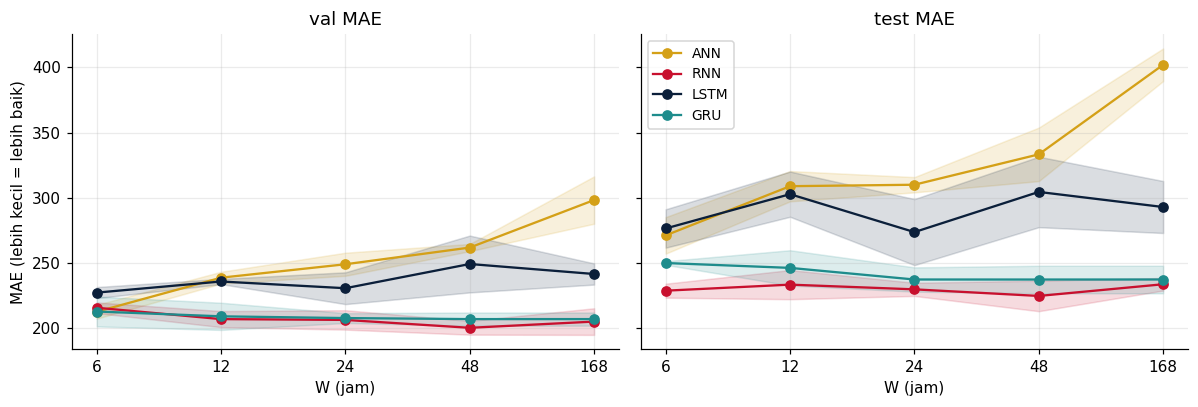

param  epoch  n_seed  val_MAE_mean  val_MAE_std  \
faktor nilai model                                                      
W      6     ANN     2465.0  166.7       3         212.4          5.3   
             RNN     5305.0  155.7       3         215.5          4.1   
             LSTM    5578.0  161.0       3         227.1          4.3   
             GRU     5397.0  202.3       3         212.6         11.5   
       12    ANN     3809.0  138.3       3         238.5          4.5   
             RNN     5305.0  154.3       3         206.7          6.2   
             LSTM    5578.0  144.7       3         235.6          2.0   
             GRU     5397.0  194.3       3         208.9         10.4   
       24    ANN     6497.0  106.3       3         248.9          8.9   
             RNN     5305.0  163.7       3         206.1          7.4   
             LSTM    5578.0  168.7       3         230.5         12.2   
             GRU     5397.0  193.7       3         207.5          3.8   
       48    ANN    11873.0   98.0       3         261.7          2.8   
             RNN     5305.0  190.3       3         200.1          5.3   
             LSTM    5578.0  149.0       3         249.1         21.8   
             GRU     5397.0  193.7       3         206.7          5.0   
       168   ANN    38753.0   76.3       3         298.2         18.2   
             RNN     5305.0  169.3       3         204.8         10.2   
             LSTM    5578.0  179.3       3         241.4          8.1   
             GRU     5397.0  193.7       3         206.7          5.1   

                    test_MAE_mean  test_MAE_std  natal_MAE_mean  natal_MAE_std  
faktor nilai model                                                              
W      6     ANN            271.0          14.0           531.4           79.6  
             RNN            228.6           5.4           454.0           34.5  
             LSTM           276.3          14.7           581.6           16.0  
             GRU            249.8           1.4           473.9           45.1  
       12    ANN            308.8          11.6           676.0          111.3  
             RNN            233.2          11.2           414.9           10.0  
             LSTM           302.7          17.4           624.0           21.2  
             GRU            246.1          13.5           478.0            7.3  
       24    ANN            309.9           5.9           680.1           52.0  
             RNN            229.6           5.1           421.2            2.4  
             LSTM           273.6          25.4           586.0           56.8  
             GRU            237.2           9.3           468.2           21.8  
       48    ANN            333.3          20.5           855.7           40.0  
             RNN            224.5          11.7           404.5            9.9  
             LSTM           304.4          27.1           602.3           98.9  
             GRU            237.1          10.6           471.1           18.6  
       168   ANN            402.0          12.5           999.3           18.0  
             RNN            233.5           4.8           432.9           42.2  
             LSTM           292.8          20.0           597.5           99.5  
             GRU            237.2          10.6           471.1           18.6

In [10]:
a1 = jalankan("A1", "W", [6, 12, 24, 48, 168])
plot_faktor(a1, "W (jam)", simpan="A1_W.png")
ringkas(a1)

### A2. Ukuran hidden ∈ {16, 32, 64, 128}

Nilai yang sama dipakai untuk keempat model (untuk ANN: neuron per lapisan tersembunyi). Akibatnya jumlah parameter **tidak lagi setara**: LSTM dengan hidden 64 punya ± 4× parameter RNN dengan hidden 64.

- Apakah model yang lebih besar selalu lebih baik pada data sekecil ini (672 sampel train)?
- Buat juga grafik MAE terhadap **jumlah parameter** (kolom `param`) dan bandingkan dengan grafik terhadap ukuran hidden.

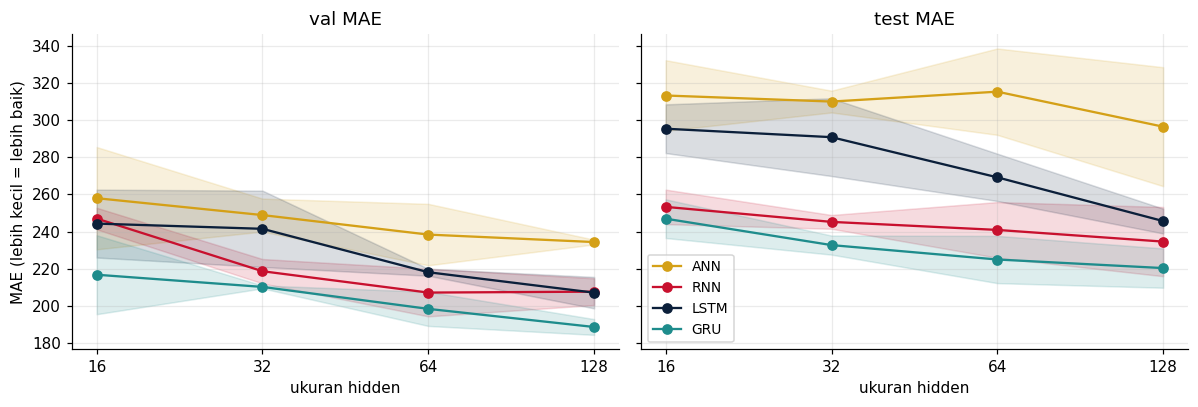

param  epoch  n_seed  val_MAE_mean  val_MAE_std  \
faktor nilai model                                                      
hidden 16    ANN     2993.0  181.7       3         257.9         27.5   
             RNN      417.0  210.3       3         247.0          5.8   
             LSTM    1617.0  205.0       3         244.3         18.3   
             GRU     1217.0  292.0       3         216.8         21.2   
       32    ANN     6497.0  106.3       3         248.9          8.9   
             RNN     1345.0  193.3       3         218.7          6.6   
             LSTM    5281.0  162.3       3         241.5         20.5   
             GRU     3969.0  199.0       3         210.2          0.8   
       64    ANN    15041.0   89.7       3         238.4         16.5   
             RNN     4737.0  150.0       3         207.2         12.8   
             LSTM   18753.0  124.7       3         218.1          1.9   
             GRU    14081.0  150.7       3         198.4          9.2   
       128   ANN    38273.0   79.3       3         234.3          1.3   
             RNN    17665.0  113.3       3         207.7          7.2   
             LSTM   70273.0  118.7       3         207.1          8.4   
             GRU    52737.0  121.7       3         188.7          4.2   

                    test_MAE_mean  test_MAE_std  natal_MAE_mean  natal_MAE_std  
faktor nilai model                                                              
hidden 16    ANN            313.2          19.0           630.4           84.1  
             RNN            253.3           9.3           415.3           11.7  
             LSTM           295.3          13.1           526.0           48.3  
             GRU            246.9          10.4           443.7            4.1  
       32    ANN            309.9           5.9           680.1           52.0  
             RNN            245.2           3.7           430.3           22.4  
             LSTM           290.8          20.9           555.2           57.7  
             GRU            232.7           5.1           423.2           14.1  
       64    ANN            315.2          23.2           580.1           22.4  
             RNN            240.9          15.0           427.4           56.4  
             LSTM           269.2          12.7           535.0           37.9  
             GRU            225.0          12.7           445.0           18.9  
       128   ANN            296.4          32.0           631.0           14.2  
             RNN            234.6          18.6           420.9           31.8  
             LSTM           245.6           6.7           491.1            7.6  
             GRU            220.3          10.6           435.2            7.5

In [11]:
a2 = jalankan("A2", "hidden", [16, 32, 64, 128])
plot_faktor(a2, "ukuran hidden", simpan="A2_hidden.png")
ringkas(a2)

### A3. Jumlah lapisan ∈ {1, 2, 3}

Acuan: ANN 2 lapisan, model rekuren 1 lapisan. Lapisan tambahan memakai ukuran hidden acuan masing-masing model.

- Apakah menumpuk lapisan rekuren membantu? Lihat juga kolom `epoch`: apakah model yang lebih dalam lebih cepat *overfit*?

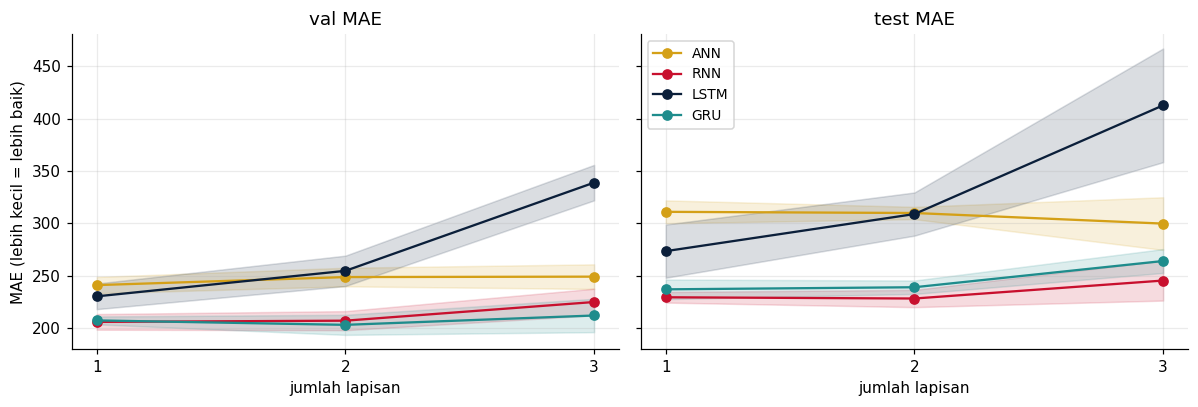

param  epoch  n_seed  val_MAE_mean  val_MAE_std  \
faktor nilai model                                                      
layers 1     ANN     5441.0  152.0       3         241.2          7.8   
             RNN     5305.0  163.7       3         206.1          7.4   
             LSTM    5578.0  168.7       3         230.5         12.2   
             GRU     5397.0  193.7       3         207.5          3.8   
       2     ANN     6497.0  106.3       3         248.9          8.9   
             RNN    14689.0  124.7       3         207.3          9.1   
             LSTM   14554.0  188.3       3         254.8         14.5   
             GRU    14289.0  156.7       3         203.3          9.6   
       3     ANN     7553.0  101.3       3         249.3         11.7   
             RNN    24073.0   96.0       3         225.1         12.7   
             LSTM   23530.0  134.0       3         338.9         16.9   
             GRU    23181.0  136.3       3         212.2         15.9   

                    test_MAE_mean  test_MAE_std  natal_MAE_mean  natal_MAE_std  
faktor nilai model                                                              
layers 1     ANN            311.0          10.9           572.2            9.4  
             RNN            229.6           5.1           421.2            2.4  
             LSTM           273.6          25.4           586.0           56.8  
             GRU            237.2           9.3           468.2           21.8  
       2     ANN            309.9           5.9           680.1           52.0  
             RNN            228.4           8.2           419.5           15.3  
             LSTM           308.9          20.6           629.3           77.2  
             GRU            239.2           6.4           438.9            4.6  
       3     ANN            299.8          25.1           626.8          112.1  
             RNN            245.5          19.1           401.8            6.3  
             LSTM           412.6          54.2           975.9          126.9  
             GRU            264.2          11.4           533.0           30.0

In [12]:
a3 = jalankan("A3", "layers", [1, 2, 3])
plot_faktor(a3, "jumlah lapisan", simpan="A3_layers.png")
ringkas(a3)

### A4. *Learning rate* ∈ {0,0001, 0,001, 0,01}

- Learning rate kecil: apakah training berhenti karena `max_epochs` sebelum konvergen? (lihat kolom `epoch` mendekati 300)
- Learning rate besar: apakah hasilnya lebih tidak stabil antar seed (simpangan baku besar)?

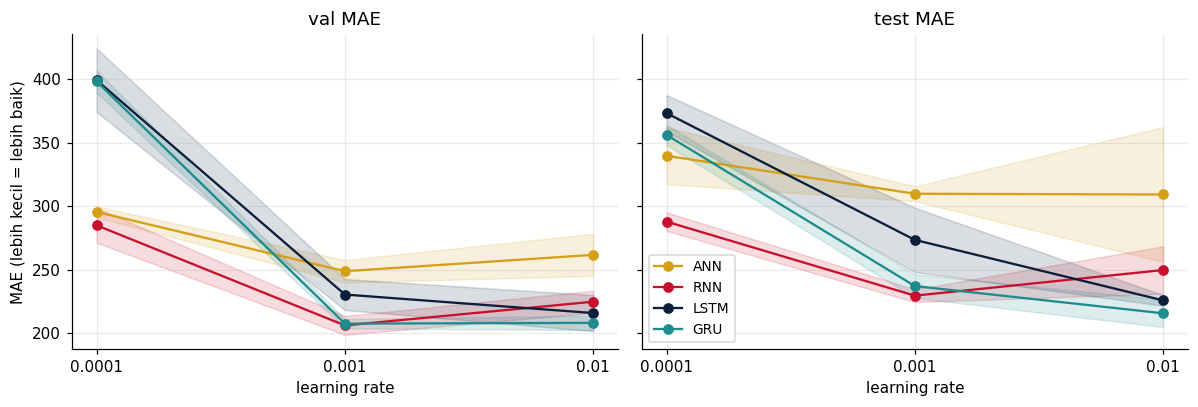

param  epoch  n_seed  val_MAE_mean  val_MAE_std  \
faktor nilai  model                                                     
lr     0.0001 ANN    6497.0  300.0       3         295.6          4.3   
              RNN    5305.0  300.0       3         285.0         13.7   
              LSTM   5578.0  300.0       3         399.4         25.0   
              GRU    5397.0  300.0       3         398.4          8.6   
       0.001  ANN    6497.0  106.3       3         248.9          8.9   
              RNN    5305.0  163.7       3         206.1          7.4   
              LSTM   5578.0  168.7       3         230.5         12.2   
              GRU    5397.0  193.7       3         207.5          3.8   
       0.01   ANN    6497.0   62.7       3         261.8         16.6   
              RNN    5305.0   81.0       3         224.8          8.7   
              LSTM   5578.0   66.0       3         215.9         14.2   
              GRU    5397.0   61.7       3         208.2          5.6   

                     test_MAE_mean  test_MAE_std  natal_MAE_mean  \
faktor nilai  model                                                
lr     0.0001 ANN            339.8          22.3           700.6   
              RNN            287.9           7.3           496.9   
              LSTM           373.5          14.3           790.9   
              GRU            356.3           7.9           718.1   
       0.001  ANN            309.9           5.9           680.1   
              RNN            229.6           5.1           421.2   
              LSTM           273.6          25.4           586.0   
              GRU            237.2           9.3           468.2   
       0.01   ANN            309.4          53.2           644.1   
              RNN            249.8          18.7           474.2   
              LSTM           225.8           4.2           502.1   
              GRU            215.7          10.9           425.4   

                     natal_MAE_std  
faktor nilai  model                 
lr     0.0001 ANN             98.7  
              RNN              5.7  
              LSTM           103.6  
              GRU             36.0  
       0.001  ANN             52.0  
              RNN              2.4  
              LSTM            56.8  
              GRU             21.8  
       0.01   ANN             27.1  
              RNN             67.4  
              LSTM            45.4  
              GRU             26.1

In [13]:
a4 = jalankan("A4", "lr", [1e-4, 1e-3, 1e-2])
plot_faktor(a4, "learning rate", simpan="A4_lr.png")
ringkas(a4)

### A5. Kelompok fitur ∈ {`net`, `net+call+sms`, `net+waktu`, `semua`}

- Fitur mana yang paling berguna: trafik telepon/SMS atau informasi jam & hari?
- Apakah model rekuren lebih membutuhkan fitur waktu dibanding ANN, atau sebaliknya? Kaitkan dengan cara masing-masing model membaca urutan.

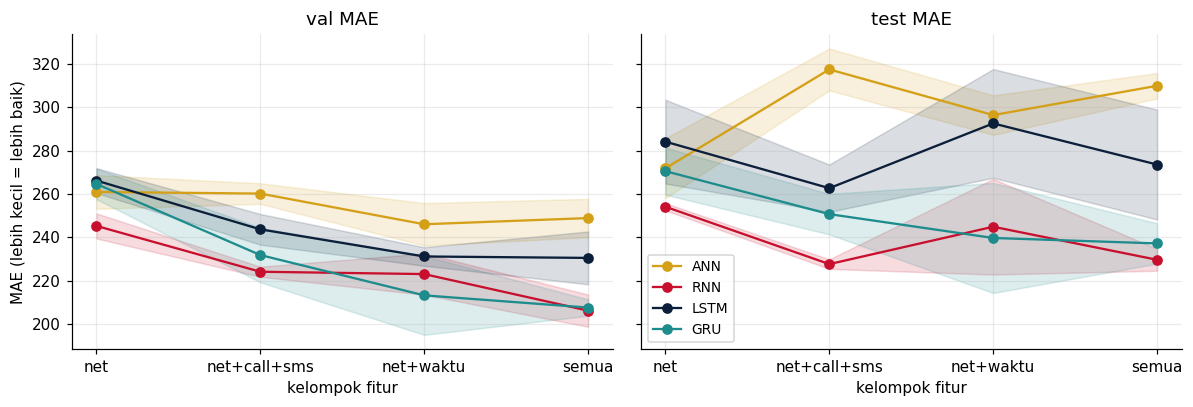

param  epoch  n_seed  val_MAE_mean  val_MAE_std  \
faktor nilai        model                                                     
fitur  net          ANN    1889.0  160.0       3         260.9          7.8   
                    RNN    4897.0  165.3       3         245.2          5.8   
                    LSTM   4786.0  223.0       3         266.2          5.7   
                    GRU    4713.0  174.7       3         264.6          7.0   
       net+call+sms ANN    3425.0  123.3       3         260.2          4.7   
                    RNN    5033.0  151.7       3         224.1          2.3   
                    LSTM   5050.0  193.3       3         243.7          7.1   
                    GRU    4941.0  201.0       3         231.8         12.6   
       net+waktu    ANN    4961.0  141.0       3         246.0          9.8   
                    RNN    5169.0  160.0       3         223.0          9.5   
                    LSTM   5314.0  170.0       3         231.1          4.3   
                    GRU    5169.0  240.7       3         213.2         18.2   
       semua        ANN    6497.0  106.3       3         248.9          8.9   
                    RNN    5305.0  163.7       3         206.1          7.4   
                    LSTM   5578.0  168.7       3         230.5         12.2   
                    GRU    5397.0  193.7       3         207.5          3.8   

                           test_MAE_mean  test_MAE_std  natal_MAE_mean  \
faktor nilai        model                                                
fitur  net          ANN            271.8          13.8           393.3   
                    RNN            254.1           1.7           543.0   
                    LSTM           284.1          19.3           561.6   
                    GRU            270.5          10.9           460.6   
       net+call+sms ANN            317.5           9.7           456.4   
                    RNN            227.6           2.2           339.8   
                    LSTM           262.7          10.9           475.5   
                    GRU            250.7           9.3           403.8   
       net+waktu    ANN            296.4           9.1           642.6   
                    RNN            244.9          22.1           512.3   
                    LSTM           292.6          25.1           656.7   
                    GRU            239.7          25.4           481.8   
       semua        ANN            309.9           5.9           680.1   
                    RNN            229.6           5.1           421.2   
                    LSTM           273.6          25.4           586.0   
                    GRU            237.2           9.3           468.2   

                           natal_MAE_std  
faktor nilai        model                 
fitur  net          ANN             31.2  
                    RNN             69.0  
                    LSTM           204.3  
                    GRU             31.2  
       net+call+sms ANN             29.6  
                    RNN             30.4  
                    LSTM            29.5  
                    GRU             18.5  
       net+waktu    ANN             65.4  
                    RNN             12.1  
                    LSTM            35.2  
                    GRU             23.2  
       semua        ANN             52.0  
                    RNN              2.4  
                    LSTM            56.8  
                    GRU             21.8

In [14]:
a5 = jalankan("A5", "fitur", ["net", "net+call+sms", "net+waktu", "semua"])
plot_faktor(a5, "kelompok fitur", simpan="A5_fitur.png")
ringkas(a5)

---
## Bagian B — Ablasi Pilihan (minimal 2 faktor)

Pilih **minimal dua** faktor berikut. Hapus tanda `#` pada sel yang dipilih. Tulis di laporan alasan memilih faktor tersebut dan hipotesis kalian **sebelum** menjalankan.

| Kode | Faktor | Nilai | Pertanyaan pemandu |
|---|---|---|---|
| B1 | `batch` | 16, 64, 256 | Batch kecil = update lebih sering tetapi lebih berisik. Mana yang lebih baik dan lebih cepat? |
| B2 | `dropout` | 0, 0,2, 0,5 | Apakah regularisasi membantu pada data sekecil ini? Coba juga dengan `layers=2`. |
| B3 | `optimizer` | adam, adamw, sgd | Apakah SGD butuh learning rate berbeda? |
| B4 | `loss` | mse, mae, huber | Loss mana yang paling baik untuk **metrik MAE**? Bagaimana dengan RMSE? |
| B5 | `patience` | 10, 30, 60 | Seberapa sensitif hasil terhadap kapan training dihentikan? |
| B6 | `horizon` | 1, 6, 24 | Pada horizon berapa model mulai kalah dari baseline naif "minggu lalu"? Bandingkan dengan tabel Bagian 0. |
| B7 | `clip` | None, 0,5, 1,0 | Apakah *gradient clipping* menstabilkan RNN, terutama dengan learning rate 0,01? |

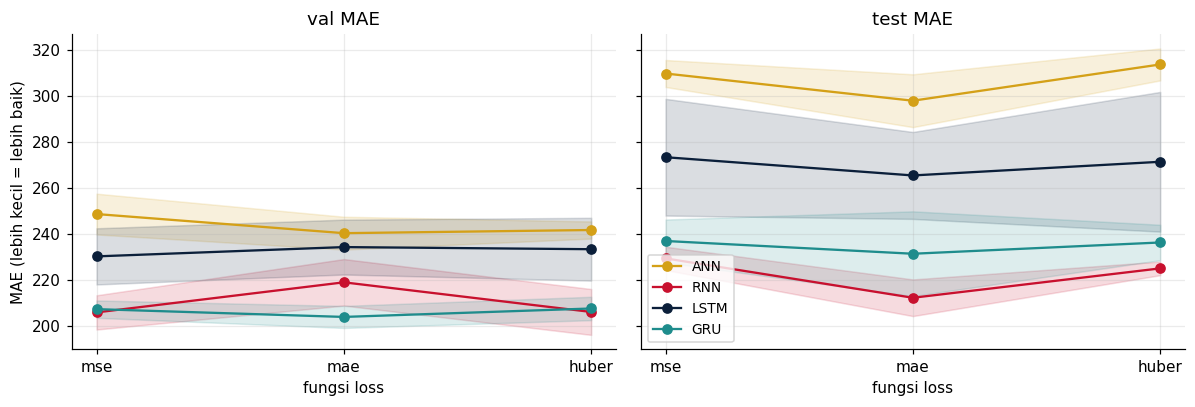

param  epoch  n_seed  val_MAE_mean  val_MAE_std  \
faktor nilai model                                                     
loss   mse   ANN    6497.0  106.3       3         248.9          8.9   
             RNN    5305.0  163.7       3         206.1          7.4   
             LSTM   5578.0  168.7       3         230.5         12.2   
             GRU    5397.0  193.7       3         207.5          3.8   
       mae   ANN    6497.0  215.3       3         240.6          7.1   
             RNN    5305.0  180.0       3         219.2         10.1   
             LSTM   5578.0  228.7       3         234.5         11.9   
             GRU    5397.0  241.7       3         204.2          4.8   
       huber ANN    6497.0  115.3       3         241.9          3.7   
             RNN    5305.0  167.7       3         206.3         10.0   
             LSTM   5578.0  168.7       3         233.6         13.6   
             GRU    5397.0  193.7       3         207.8          5.1   

                    test_MAE_mean  test_MAE_std  natal_MAE_mean  natal_MAE_std  
faktor nilai model                                                              
loss   mse   ANN            309.9           5.9           680.1           52.0  
             RNN            229.6           5.1           421.2            2.4  
             LSTM           273.6          25.4           586.0           56.8  
             GRU            237.2           9.3           468.2           21.8  
       mae   ANN            298.1          11.5           566.6           34.1  
             RNN            212.5           8.0           417.0           20.1  
             LSTM           265.6          18.9           522.9           24.3  
             GRU            231.6          18.4           480.7           13.4  
       huber ANN            313.9           6.9           629.7           67.1  
             RNN            225.3           3.0           415.3           15.7  
             LSTM           271.6          30.3           583.1           65.3  
             GRU            236.5           7.7           462.9           22.3

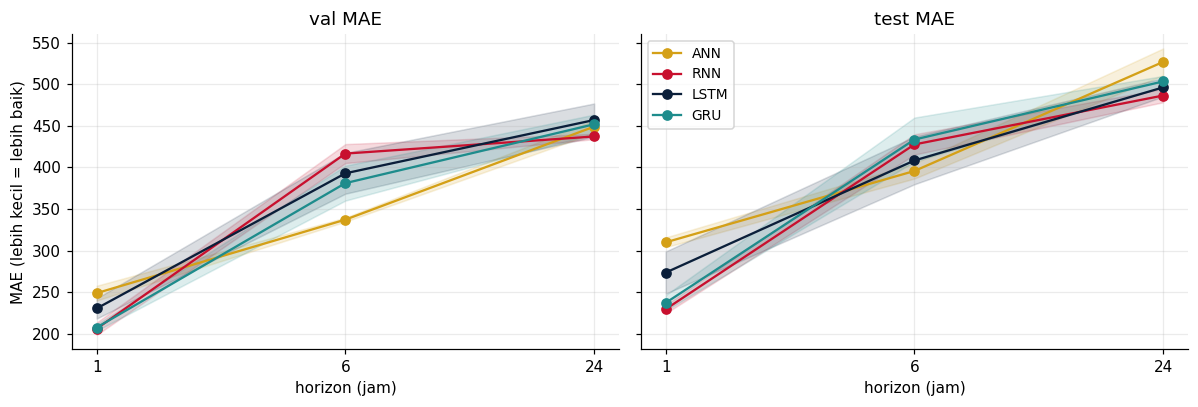

param  epoch  n_seed  val_MAE_mean  val_MAE_std  \
faktor  nilai model                                                     
horizon 1     ANN    6497.0  106.3       3         248.9          8.9   
              RNN    5305.0  163.7       3         206.1          7.4   
              LSTM   5578.0  168.7       3         230.5         12.2   
              GRU    5397.0  193.7       3         207.5          3.8   
        6     ANN    6662.0  120.7       3         337.2          2.4   
              RNN    5650.0  119.3       3         416.6         11.4   
              LSTM   5748.0  210.0       3         392.9         24.5   
              GRU    5592.0  204.7       3         381.1         21.0   
        24    ANN    7256.0  154.3       3         449.0          7.6   
              RNN    6892.0  208.7       3         437.2          3.2   
              LSTM   6360.0  199.7       3         456.9         19.8   
              GRU    6294.0  193.0       3         451.8         11.6   

                     test_MAE_mean  test_MAE_std  natal_MAE_mean  \
faktor  nilai model                                                
horizon 1     ANN            309.9           5.9           680.1   
              RNN            229.6           5.1           421.2   
              LSTM           273.6          25.4           586.0   
              GRU            237.2           9.3           468.2   
        6     ANN            395.7           9.1           901.7   
              RNN            427.6          12.2           953.2   
              LSTM           408.3          28.6           942.3   
              GRU            433.4          26.4           962.4   
        24    ANN            526.8          16.1          1199.4   
              RNN            486.4           8.1          1101.6   
              LSTM           496.1          10.9          1150.5   
              GRU            503.3           6.5          1108.1   

                     natal_MAE_std  
faktor  nilai model                 
horizon 1     ANN             52.0  
              RNN              2.4  
              LSTM            56.8  
              GRU             21.8  
        6     ANN             23.7  
              RNN             43.2  
              LSTM            40.9  
              GRU             55.7  
        24    ANN             30.9  
              RNN             17.6  
              LSTM             7.2  
              GRU             33.5

In [15]:
# b1 = jalankan("B1", "batch", [16, 64, 256]);              plot_faktor(b1, "batch size", simpan="B1_batch.png");     display(ringkas(b1))
# b2 = jalankan("B2", "dropout", [0.0, 0.2, 0.5]);           plot_faktor(b2, "dropout", simpan="B2_dropout.png");      display(ringkas(b2))
# b3 = jalankan("B3", "optimizer", ["adam", "adamw", "sgd"]); plot_faktor(b3, "optimizer", simpan="B3_optimizer.png"); display(ringkas(b3))
b4 = jalankan("B4", "loss", ["mse", "mae", "huber"]);       plot_faktor(b4, "fungsi loss", simpan="B4_loss.png");    display(ringkas(b4))
# b5 = jalankan("B5", "patience", [10, 30, 60]);              plot_faktor(b5, "patience", simpan="B5_patience.png");   display(ringkas(b5))
b6 = jalankan("B6", "horizon", [1, 6, 24]);                 plot_faktor(b6, "horizon (jam)", simpan="B6_horizon.png"); display(ringkas(b6))
# b7 = jalankan("B7", "clip", [None, 0.5, 1.0], lr=1e-2);     plot_faktor(b7, "clip (lr = 0,01)", simpan="B7_clip.png"); display(ringkas(b7))

---
## Bagian C — Konfigurasi Terbaik per Model

1. Untuk **setiap model**, gabungkan nilai terbaik dari Bagian A dan B berdasarkan **val MAE rata-rata** (bukan test!).
2. Isi `TERBAIK` di bawah. Cukup tulis kunci yang berbeda dari acuan. Biarkan `horizon` = 1 agar sebanding dengan acuan.
3. Gabungan nilai terbaik belum tentu terbaik bersama-sama (faktor bisa saling memengaruhi). Bila val MAE gabungan lebih buruk dari acuan, boleh mencoba beberapa kombinasi lagi dengan label bagian `"C-coba1"`, `"C-coba2"`, dst. Semua percobaan tetap dilaporkan.

In [16]:
hasil_ablasi = pd.read_csv(CSV_HASIL)

BAGIAN_FAKTOR = {
    "W": "A1",
    "hidden": "A2",
    "layers": "A3",
    "lr": "A4",
    "fitur": "A5",
    "loss": "B4",
}

TERBAIK = {m: {} for m in MODELS}
catatan_pilihan = []

for m in MODELS:
    for faktor, bagian in BAGIAN_FAKTOR.items():
        data = hasil_ablasi[
            (hasil_ablasi["bagian"] == bagian) &
            (hasil_ablasi["model"] == m)
        ]

        if data.empty:
            raise ValueError(
                f"Hasil {bagian} untuk model {m} belum tersedia."
            )

        skor = (
            data.groupby("nilai")["val_MAE"]
            .mean()
            .sort_values()
        )

        nilai = skor.index[0]

        if faktor in ["W", "hidden", "layers"]:
            nilai = int(float(nilai))
        elif faktor == "lr":
            nilai = float(nilai)
        else:
            nilai = str(nilai)

        TERBAIK[m][faktor] = nilai

        catatan_pilihan.append({
            "model": m,
            "faktor": faktor,
            "bagian": bagian,
            "nilai_terpilih": nilai,
            "rata_rata_val_MAE": skor.iloc[0]
        })

    # Horizon tetap 1 agar sebanding dengan acuan
    TERBAIK[m]["horizon"] = 1

# Tampilkan nilai faktor terpilih
tabel_pilihan = pd.DataFrame(catatan_pilihan)
display(tabel_pilihan.round({"rata_rata_val_MAE": 3}))

# Jalankan konfigurasi gabungan
c = jalankan_konfigurasi("C", TERBAIK)

# Bandingkan dengan konfigurasi acuan
banding = pd.concat([
    acuan.assign(konfigurasi="acuan"),
    c.assign(konfigurasi="terbaik")
])

tabel_c = (
    banding.groupby(["model", "konfigurasi"])[
        ["param", "val_MAE", "test_MAE", "test_MAPE", "natal_MAE"]
    ]
    .agg(["mean", "std"])
    .round(1)
)

tabel_c.to_csv(HASIL_DIR / "C_terbaik_vs_acuan.csv")
display(tabel_c)

,model,faktor,bagian,nilai_terpilih,rata_rata_val_MAE
0,ANN,W,A1,6,212.398
1,ANN,hidden,A2,128,234.348
2,ANN,layers,A3,1,241.181
3,ANN,lr,A4,0.001,248.860
4,ANN,fitur,A5,net+waktu,246.001
5,ANN,loss,B4,mae,240.553
6,RNN,W,A1,48,200.066
7,RNN,hidden,A2,64,207.169
8,RNN,layers,A3,1,206.119
9,RNN,lr,A4,0.001,206.119


param          val_MAE       test_MAE       test_MAPE  \
                      mean      std    mean   std     mean   std      mean   
model konfigurasi                                                            
ANN   acuan         6497.0      0.0   248.9   8.9    309.9   5.9      11.3   
      terbaik       5297.0   1314.5   238.8  12.8    293.6  21.3       9.9   
GRU   acuan         5397.0      0.0   207.5   3.8    237.2   9.3       8.0   
      terbaik      78603.0  80193.2   216.3  10.8    233.8  15.7       8.0   
LSTM  acuan         5578.0      0.0   230.5  12.2    273.6  25.4       9.1   
      terbaik      37925.5  35434.9   225.5  13.4    258.9  25.5       8.7   
RNN   acuan         5305.0      0.0   206.1   7.4    229.6   5.1       8.5   
      terbaik       5021.0    311.1   209.4  11.8    238.6  17.2       9.2   

                       natal_MAE        
                   std      mean   std  
model konfigurasi                       
ANN   acuan        0.8     680.1  52.0  
      terbaik      1.6     639.2  62.4  
GRU   acuan        0.7     468.2  21.8  
      terbaik      0.8     483.5  36.1  
LSTM  acuan        1.0     586.0  56.8  
      terbaik      1.0     542.2  60.2  
RNN   acuan        0.3     421.2   2.4  
      terbaik      1.1     427.1  34.7

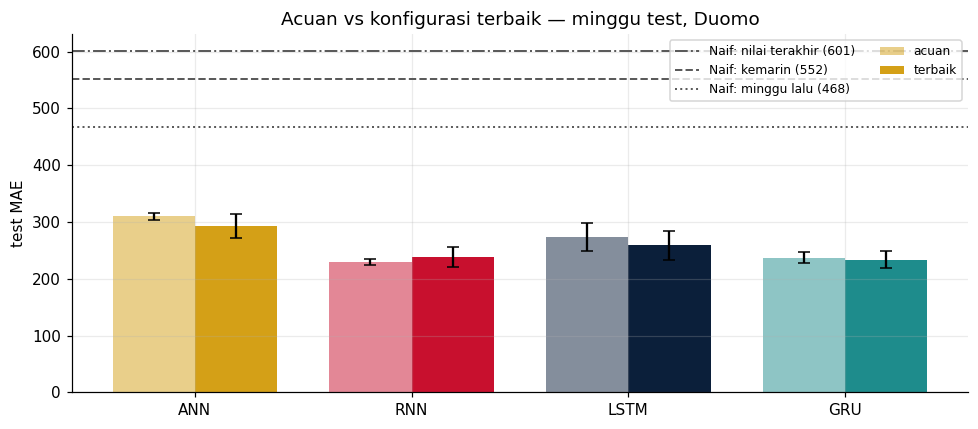

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
x, lebar = np.arange(len(MODELS)), 0.38
for j, (nama, df, alpha) in enumerate([("acuan", acuan, 0.5), ("terbaik", c, 1.0)]):
    r = df.groupby("model")["test_MAE"].agg(["mean", "std"]).reindex(MODELS)
    ax.bar(x + (j - 0.5) * lebar, r["mean"], lebar, yerr=r["std"], capsize=4, alpha=alpha,
           color=[WARNA_MODEL[m] for m in MODELS], label=nama)
for nama, gaya in {"Naif: nilai terakhir": "-.", "Naif: kemarin": "--", "Naif: minggu lalu": ":"}.items():
    v = naif.query("horizon == 1 and split == 'test' and model == @nama").MAE.item()
    ax.axhline(v, color=GRAY, ls=gaya, lw=1.3, label=f"{nama} ({v:.0f})")
ax.set_xticks(x, MODELS); ax.set_ylabel("test MAE"); ax.legend(fontsize=8, ncol=2)
ax.set_title("Acuan vs konfigurasi terbaik — minggu test, Duomo")
plt.tight_layout(); plt.savefig(HASIL_DIR / "C_terbaik_vs_acuan.png", dpi=200, bbox_inches="tight"); plt.show()

---
## Bagian D — Uji Generalisasi di Lokasi Kelompok

Latih ulang konfigurasi **acuan** dan **terbaik** (dari Bagian C, tanpa diubah) di lokasi kelompok kalian, lalu bandingkan dengan baseline naif lokasi tersebut.

- Apakah urutan model (siapa terbaik) sama dengan di Duomo?
- Apakah konfigurasi terbaik Duomo tetap lebih baik dari acuan di lokasi kalian? Jika tidak, apa bedanya pola trafik lokasi kalian (lihat grafik di bawah)?
- Bagaimana dengan minggu Natal di lokasi kalian?

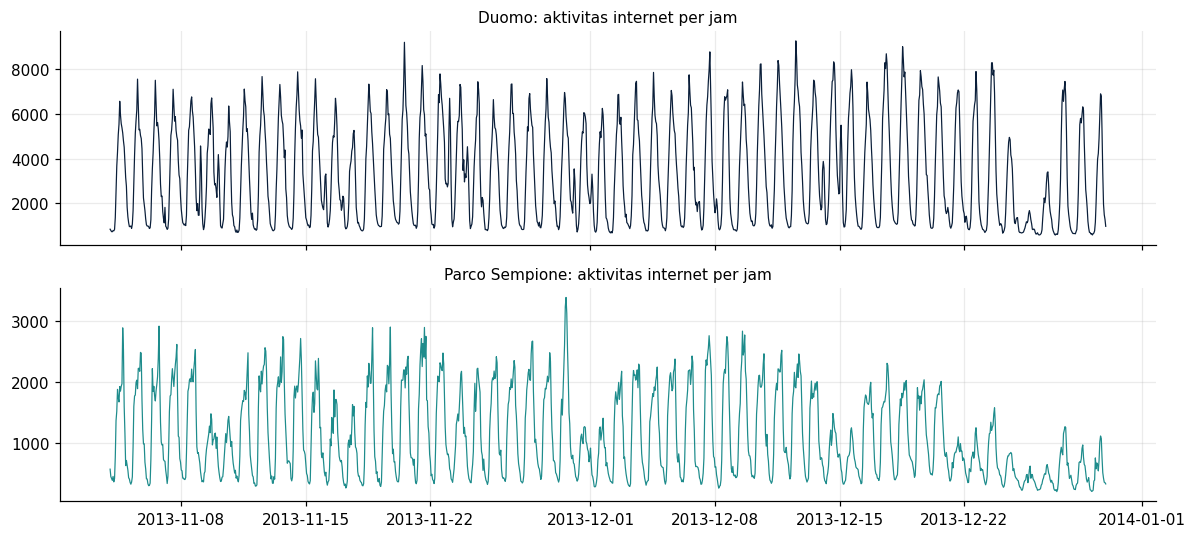

split,natal,test,val
model,,,
Naif: kemarin,177.9,231.2,232.9
Naif: minggu lalu,531.6,167.8,300.8
Naif: nilai terakhir,77.6,137.8,175.0


In [18]:
dfk, dfd = muat_data(LOKASI_KELOMPOK), muat_data("duomo")
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for ax, df, nama, warna in [(axes[0], dfd, "Duomo", NAVY), (axes[1], dfk, nama_lokasi(LOKASI_KELOMPOK), TEAL)]:
    ax.plot(df.index, df.net, color=warna, lw=0.8)
    ax.set_title(f"{nama}: aktivitas internet per jam", fontsize=10)
plt.tight_layout(); plt.savefig(HASIL_DIR / "D_pola_lokasi.png", dpi=200, bbox_inches="tight"); plt.show()

naif_k = baseline_naif(LOKASI_KELOMPOK, 1)
naif_k.to_csv(HASIL_DIR / "baseline_naif_lokasi.csv", index=False)
naif_k.pivot_table(index="model", columns="split", values="MAE").round(1)

In [19]:
d_acuan = jalankan("D-acuan", "lokasi", [LOKASI_KELOMPOK])
d_terbaik = jalankan_konfigurasi("D-terbaik", TERBAIK, lokasi=LOKASI_KELOMPOK)
banding_d = pd.concat([d_acuan.assign(konfigurasi="acuan"), d_terbaik.assign(konfigurasi="terbaik")])
tabel_d = banding_d.groupby(["model", "konfigurasi"])[["val_MAE", "test_MAE", "test_MAPE", "natal_MAE"]].agg(["mean", "std"]).round(1)
tabel_d.to_csv(HASIL_DIR / "D_generalisasi.csv")
print("Lokasi:", nama_lokasi(LOKASI_KELOMPOK))
tabel_d

Lokasi: Parco Sempione


val_MAE       test_MAE       test_MAPE      natal_MAE      
                     mean   std     mean   std      mean  std      mean   std
model konfigurasi                                                            
ANN   acuan         113.2   5.7    117.8   3.6      11.5  0.4     243.4  25.2
      terbaik       109.4   5.4    108.6  10.9      10.7  1.0     244.9  21.4
GRU   acuan         107.2   3.8    108.4   8.9      10.9  0.9     217.4  28.3
      terbaik       107.1   3.0    105.6   7.7      10.6  0.8     231.8  28.0
LSTM  acuan         121.3  14.7    119.8  19.2      12.0  2.8     309.6  55.3
      terbaik       113.7  12.5    108.9  17.2      10.6  2.4     284.5  46.2
RNN   acuan         104.2   1.5     99.5   2.7      10.0  0.4     185.3  13.8
      terbaik       105.3   3.7     99.7   3.3      10.0  0.5     184.1   9.5

---
## Penutup — Cek Sebelum Mengumpulkan

- [ ] `CEPAT = False` dan semua sel sudah dijalankan berurutan tanpa error.
- [ ] `hasil/ablasi.csv` berisi seluruh run (3 seed per konfigurasi).
- [ ] Setiap angka dan grafik di laporan bisa dilacak ke `hasil/` di repo.
- [ ] Notebook di-commit **beserta output-nya**.
- [ ] README repo memuat nama & NIM seluruh anggota, kelas, dan kode lokasi.

In [20]:
semua = baca_hasil()
print(len(semua), "run tercatat |", semua.groupby("bagian").size().to_dict())
print("Total waktu training: {:.1f} menit".format(semua.drop_duplicates("kunci").detik.sum() / 60))

372 run tercatat | {'0': 12, 'A1': 60, 'A2': 48, 'A3': 36, 'A4': 36, 'A5': 48, 'B4': 36, 'B6': 36, 'C': 24, 'D-acuan': 12, 'D-terbaik': 24}
Total waktu training: 130.7 menit
